# One-Class SVM anomaly detection: performance and computing cost

This notebook measures how well the **One-Class SVM** from `SVM.ipynb` detects anomalies on P-1, and estimates what it would cost to run. It follows the same pipeline as `SVM.ipynb`.

The SVM learns a boundary around the (anomaly-free) training data's engineered features. Any test row outside that boundary is flagged as anomalous. Flagged rows are grouped into alert intervals, and small clusters (fewer than `min_flags` flagged rows) are discarded. The remaining alerts are scored against the expert labels with `evaluate_event_detection()` from `detection.py`.

## Measurements

- Events detected, missed events, false alerts, and event precision, recall, and F1.
- Training (fit) time, reported separately from repeated scoring time.
- Feature-generation, scoring, interval-construction, and complete-pipeline time.
- Peak memory use.
- Estimated monthly computing expense under an explicit AWS Fargate scenario.

## Load P-1 data and labels

In [1]:
from pathlib import Path
import sys
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

repo_dir = Path.cwd().parent
data_dir = repo_dir / "data" / "data"

if str(repo_dir) not in sys.path:
    sys.path.insert(0, str(repo_dir))

from detection import evaluate_event_detection

channel = "P-1"

train = pd.DataFrame(np.load(data_dir / "train" / f"{channel}.npy"))
test = pd.DataFrame(np.load(data_dir / "test" / f"{channel}.npy"))

labels = pd.read_csv(data_dir / "labeled_anomalies.csv")
labeled_intervals = ast.literal_eval(
    labels.loc[labels["chan_id"] == channel, "anomaly_sequences"].iloc[0])

print("Training shape:", train.shape)
print("Test shape:", test.shape)
print("Known anomaly intervals:", sorted(labeled_intervals))

Training shape: (2872, 25)
Test shape: (8505, 25)
Known anomaly intervals: [[2149, 2349], [3539, 3779], [4536, 4844]]


## Feature engineering

Same steps as `SVM.ipynb`:

1. On the **raw training data**, find command columns (1–24) that are constant or highly correlated (|r| > 0.95) with an earlier command column, and drop them from both train and test.
2. Build rolling-window features: the current value, rolling mean/min/max/std, the first difference and its rolling std, and rolling sums of every remaining column.

The window length is not fixed here; it is chosen by cross-validation in the next section.

In [2]:
OHF = range(1, 25)
corr = train[OHF].corr().abs()
const_cols = corr.columns[corr.isna().all()].tolist()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
corr_cols = [col for col in upper.columns if (upper[col] > 0.95).any()]
to_drop = const_cols + corr_cols

train = train.drop(columns=to_drop)
test = test.drop(columns=to_drop)


def feature_engineering(df, wind):
    features = pd.DataFrame()
    features["value"] = df[0]
    features["rmean"] = df[0].rolling(window=wind).mean()
    features["diff"] = df[0].diff()
    features["diff_std"] = df[0].diff().rolling(window=wind).std()
    features["rmin"] = df[0].rolling(window=wind).min()
    features["rmax"] = df[0].rolling(window=wind).max()
    features["rstd"] = df[0].rolling(window=wind).std()
    for i in df.columns:
        features[f"feature {i}"] = df[i].rolling(window=wind).sum()
    return features.iloc[wind:]


print("Dropped columns:", to_drop)
print("Remaining columns:", list(train.columns))

Dropped columns: [4, 8, 10, 12, 15, 16, 20, 23, 24, 14, 18, 22]
Remaining columns: [0, 1, 2, 3, 5, 6, 7, 9, 11, 13, 17, 19, 21]


## Select the configuration using chronological validation on the training data

As in `SVM.ipynb`, we search over:

- window length in {5, 10, 15, 20},
- feature set: all features or telemetry only (the first 7 features),
- `gamma` in {0.1, 0.01, 0.001},
- `nu` in {0.01, 0.03, 0.05, 0.07, 0.1},

using a 15-split `TimeSeriesSplit` (gap = window) on the training features.

Because the training data contains no anomalies, every flagged validation row is a **false positive**, so candidates are compared by mean validation false-positive rate (FPR). We choose the lowest mean FPR, breaking ties with the smaller window. No test data or labels are used for this choice.

We also set `min_flags` from the validation folds. Validation flags are grouped like test flags (flags at most `window` rows apart form one cluster). `min_flags` is one more than the largest false cluster, so no false cluster seen in validation would have raised an alert.

Note: choosing the lowest FPR also tends to favour the most permissive boundary, so this rule can trade away sensitivity.

In [3]:
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit

window_values = [5, 10, 15, 20]
gamma_values = [0.1, 0.01, 0.001]
nu_values = [0.01, 0.03, 0.05, 0.07, 0.1]
n_splits = 15

def make_model(gamma, nu):
    return Pipeline(steps=[
        ("Scaler", StandardScaler()),
        ("SVM", OneClassSVM(nu=nu, gamma=gamma))])

def build_features(df, wind, telemetry_only):
    feats = feature_engineering(df, wind)
    return feats.iloc[:, :7] if telemetry_only else feats

cv_rows = []
for w in window_values:
    for tel_only in [False, True]:
        feats = build_features(train, w, tel_only)
        tscv = TimeSeriesSplit(n_splits=n_splits, gap=w)
        for g in gamma_values:
            for n in nu_values:
                fprs, val_flagged = [], []
                for fit_idx, val_idx in tscv.split(feats):
                    model = make_model(g, n).fit(feats.iloc[fit_idx])
                    val_pred = model.predict(feats.iloc[val_idx]) == -1
                    fprs.append(val_pred.mean())
                    val_flagged.extend(feats.index[val_idx][val_pred])

                # Every validation flag is a false alarm; find the largest false cluster
                val_flagged = np.sort(np.asarray(val_flagged))
                breaks = np.where(np.diff(val_flagged) > w)[0]
                cluster_sizes = np.diff(np.r_[0, breaks + 1, len(val_flagged)])
                max_false_cluster = int(cluster_sizes.max()) if len(val_flagged) else 0

                cv_rows.append({"window": w, "telemetry_only": tel_only,
                                "gamma": g, "nu": n, "mean_val_FPR": np.mean(fprs),
                                "max_false_cluster": max_false_cluster})

cv_summary = (pd.DataFrame(cv_rows)
              .sort_values(["mean_val_FPR", "window"])
              .reset_index(drop=True))
display(cv_summary.head(10))

best = cv_summary.iloc[0]
window = int(best["window"])
selected_gamma = float(best["gamma"])
selected_nu = float(best["nu"])
telemetry_only = bool(best["telemetry_only"])
min_flags = int(best["max_false_cluster"]) + 1
print(f"Selected: window={window}, gamma={selected_gamma}, nu={selected_nu}, "
      f"telemetry_only={telemetry_only}, min_flags={min_flags}")

,window,telemetry_only,gamma,nu,mean_val_FPR,max_false_cluster
0,10,True,0.001,0.01,0.017978,7
1,10,True,0.010,0.01,0.019101,7
2,5,True,0.001,0.01,0.019367,12
3,10,False,0.001,0.01,0.019850,10
4,5,False,0.001,0.01,0.020484,9
5,5,True,0.010,0.01,0.020484,12
6,15,True,0.001,0.01,0.026592,14
7,15,True,0.010,0.01,0.029588,16
8,5,False,0.010,0.01,0.030168,11
9,20,True,0.001,0.01,0.032959,19


Selected: window=10, gamma=0.001, nu=0.01, telemetry_only=True, min_flags=8


## Fit on all training data and score the test sequence

The selected model is refit on all training feature rows. Test features use the same window and columns. Each test feature row keeps its original test index (`window` onward), so flagged rows map directly to test time steps.

In [4]:
train_features = build_features(train, window, telemetry_only)
svm_model = make_model(selected_gamma, selected_nu).fit(train_features)

def build_test_features(test_df):
    return build_features(test_df, window, telemetry_only)

def generate_svm_flags(test_df, fitted_model):
    # Return the test indices flagged as outside the learned boundary
    features = build_test_features(test_df)
    flagged = fitted_model.predict(features) == -1
    return features.index.to_numpy()[flagged]

test_features = build_test_features(test)
flagged_indices = generate_svm_flags(test, svm_model)

print("Training feature rows:", train_features.shape)
print("Evaluated test rows:", len(test_features))
print("Flagged rows:", len(flagged_indices),
      f"({len(flagged_indices) / len(test_features):.1%})")

Training feature rows: (2862, 7)
Evaluated test rows: 8495
Flagged rows: 301 (3.5%)


## Turn flagged rows into alert intervals

Because every feature row summarises the previous `window` readings, one unusual reading can flip nearby rows on and off. We therefore merge flags separated by no more than `window` steps into one alert, then drop alerts with fewer than `min_flags` flagged rows. Both settings come from the training data, not the test labels.

For comparison, we also report the raw consecutive grouping and the merged grouping without the `min_flags` filter.

In [5]:
def flags_to_intervals(indices, max_gap=1, min_flags=1):
    # Group sorted indices into inclusive (start, end) intervals.
    # Flags whose spacing is <= max_gap join the same interval.
    # Intervals containing fewer than min_flags flagged rows are dropped.
    if len(indices) == 0:
        return []
    indices = np.sort(np.asarray(indices))
    breaks = np.where(np.diff(indices) > max_gap)[0]
    starts = np.r_[indices[0], indices[breaks + 1]]
    ends = np.r_[indices[breaks], indices[-1]]
    counts = np.diff(np.r_[0, breaks + 1, len(indices)])
    keep = counts >= min_flags
    return [(int(s), int(e)) for s, e in zip(starts[keep], ends[keep])]

raw_intervals = flags_to_intervals(flagged_indices, max_gap=1)
merged_intervals = flags_to_intervals(flagged_indices, max_gap=window)
svm_intervals = flags_to_intervals(flagged_indices, max_gap=window, min_flags=min_flags)

groupings = [
    ("Raw (gap = 1)", raw_intervals),
    (f"Merged (gap = {window})", merged_intervals),
    (f"Merged + min_flags = {min_flags} (final)", svm_intervals),
]
evaluations = [evaluate_event_detection(iv, labeled_intervals) for _, iv in groupings]
svm_evaluation = evaluations[-1]

print("Final alert intervals:", svm_intervals)

event_order = sorted(range(len(labeled_intervals)), key=lambda i: labeled_intervals[i][0])
for n, i in enumerate(event_order, start=1):
    status = "Detected" if svm_evaluation["detected_event_mask"][i] else "Missed"
    print(f"Event {n} {labeled_intervals[i]}: {status}")

detection_results = pd.DataFrame([
    {"grouping": name, "alert intervals": len(iv), "TP": ev["TP"], "FP": ev["FP"],
     "FN": ev["FN"], "precision": ev["precision"], "recall": ev["recall"], "F1": ev["f1"]}
    for (name, iv), ev in zip(groupings, evaluations)
]).set_index("grouping")
detection_results

Final alert intervals: [(907, 935), (2183, 2257), (2604, 2613), (3554, 3621), (3641, 3701), (4832, 4841)]
Event 1 [2149, 2349]: Detected
Event 2 [3539, 3779]: Detected
Event 3 [4536, 4844]: Detected


,alert intervals,TP,FP,FN,precision,recall,F1
grouping,,,,,,,
Raw (gap = 1),74,3,64,0,0.044776,1.0,0.085714
Merged (gap = 10),48,3,43,0,0.065217,1.0,0.122449
Merged + min_flags = 8 (final),6,3,2,0,0.600000,1.0,0.750000


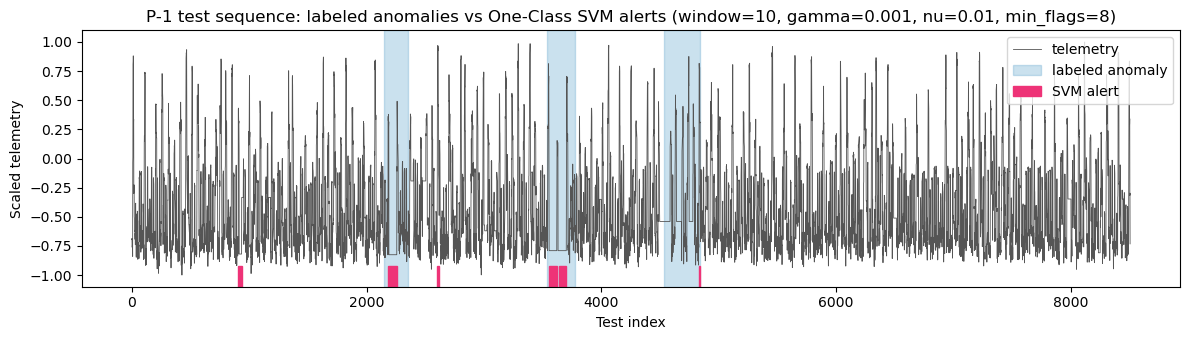

In [6]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(test.index, test[0], lw=0.6, color="#555555", label="telemetry")
for k, (s, e) in enumerate(labeled_intervals):
    ax.axvspan(s, e, color="#67a9cf", alpha=0.35, label="labeled anomaly" if k == 0 else None)
for k, (s, e) in enumerate(svm_intervals):
    ax.axvspan(s, e, ymin=0, ymax=0.08, color="#EE3377", label="SVM alert" if k == 0 else None)
ax.set_title(f"P-1 test sequence: labeled anomalies vs One-Class SVM alerts "
             f"(window={window}, gamma={selected_gamma}, nu={selected_nu}, min_flags={min_flags})")
ax.set_xlabel("Test index")
ax.set_ylabel("Scaled telemetry")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## Computational benchmark

Measurement procedure:

1. One warm-up run before measuring.
2. Seven repetitions; `timeit.autorange()` picks enough calls per repeat for at least ~0.2 s.
3. Report the median and interquartile range in milliseconds per batch (the full P-1 test sequence).
4. Limit numerical libraries to one thread.

Stages:

- **Feature generation:** rolling-window features for the test sequence.
- **Scoring:** scaler + One-Class SVM `predict` on precomputed features.
- **Interval construction:** grouping flagged rows into alerts and applying `min_flags`.
- **Complete pipeline:** raw test data to alert intervals in one call.

Model fitting is a one-off training cost and is timed separately. Data loading, plotting, and label evaluation are excluded.

In [7]:
import timeit
from threadpoolctl import threadpool_limits

def run_complete_svm_pipeline():
    return flags_to_intervals(generate_svm_flags(test, svm_model),
                              max_gap=window, min_flags=min_flags)

assert run_complete_svm_pipeline() == svm_intervals

operations = {
    "Feature generation": lambda: build_test_features(test),
    "Scoring": lambda: svm_model.predict(test_features),
    "Interval construction": lambda: flags_to_intervals(flagged_indices, max_gap=window,
                                                         min_flags=min_flags),
    "Complete pipeline": run_complete_svm_pipeline,
}

runtime_rows = []
with threadpool_limits(limits=1):
    for stage, operation in operations.items():
        operation()  # warm-up
        timer = timeit.Timer(operation)
        calls_per_repeat, _ = timer.autorange()
        ms = np.asarray(timer.repeat(repeat=7, number=calls_per_repeat)) / calls_per_repeat * 1000
        runtime_rows.append({
            "stage": stage,
            "calls per repeat": calls_per_repeat,
            "median_ms": np.median(ms),
            "q25_ms": np.percentile(ms, 25),
            "q75_ms": np.percentile(ms, 75)})

    # Training cost, timed separately
    fit_ms = np.asarray(timeit.Timer(lambda: make_model(selected_gamma, selected_nu).fit(train_features))
                        .repeat(repeat=5, number=1)) * 1000

svm_runtime = pd.DataFrame(runtime_rows).set_index("stage")
display(svm_runtime)
print(f"Training (fit) median: {np.median(fit_ms):.1f} ms "
      f"(IQR {np.percentile(fit_ms, 25):.1f}-{np.percentile(fit_ms, 75):.1f} ms)")

,calls per repeat,median_ms,q25_ms,q75_ms
stage,,,,
Feature generation,20,20.614110,19.080813,23.456438
Scoring,10,44.900320,38.091265,49.052185
Interval construction,5000,0.077169,0.075265,0.087605
Complete pipeline,5,80.802620,69.065520,86.825430


Training (fit) median: 15.4 ms (IQR 13.7-21.7 ms)


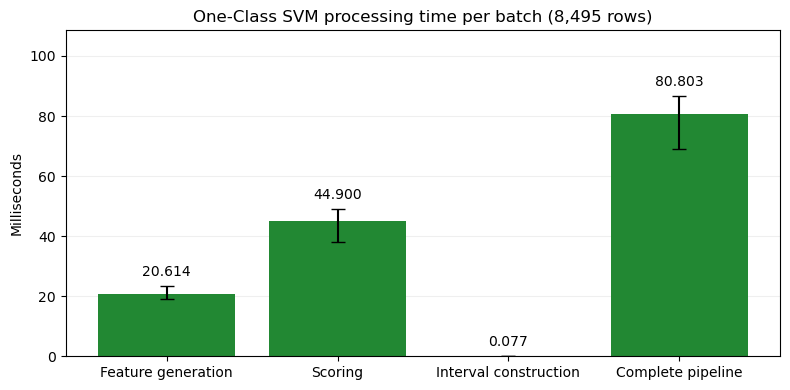

In [8]:
med = svm_runtime["median_ms"].to_numpy()
err = np.vstack([med - svm_runtime["q25_ms"], svm_runtime["q75_ms"] - med])

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(svm_runtime.index, med, yerr=err, capsize=5, color="#228833")
ax.bar_label(bars, labels=[f"{v:.3f}" for v in med], padding=5)
ax.set_title(f"One-Class SVM processing time per batch ({len(test_features):,} rows)")
ax.set_ylabel("Milliseconds")
ax.set_ylim(0, svm_runtime["q75_ms"].max() * 1.25)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### Peak memory

Measured with `tracemalloc` in a separate run, so monitoring overhead does not affect the timings above. `tracemalloc` tracks Python-level allocations (including NumPy arrays), not total process memory.

In [9]:
import tracemalloc

def peak_memory_mb(operation):
    tracemalloc.start()
    operation()
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / 1024**2

pd.Series({
    "Training (fit)": peak_memory_mb(lambda: make_model(selected_gamma, selected_nu).fit(train_features)),
    "Complete pipeline": peak_memory_mb(run_complete_svm_pipeline),
}, name="peak MB").to_frame()

,peak MB
Training (fit),0.384277
Complete pipeline,1.780164


## Illustrative ground-computing cost scenario

**Price reference:** [AWS Fargate pricing](https://aws.amazon.com/fargate/pricing/), Example 1, Linux/x86, US East (N. Virginia): **\$0.000011244** per vCPU-second and **\$0.000001235** per GB-second, per-second billing with a one-minute minimum, rounded up to whole seconds. The pipeline has not been deployed on AWS.

**Assumptions:**

- Allocate **1 vCPU and 2 GB of memory**.
- Process **1,000 P-1-sized batches per day** for **30 days**.
- One task per day, batches processed sequentially, then the task terminates.
- **30 seconds per daily task** of startup and other overhead.
- Cloud processing times of **0.5×, 1×, and 2×** the local benchmark.
- Exclude parameter selection, storage, networking, logging, taxes, and human alert investigation. Training is reported separately as a one-off cost.

With $t_{\mathrm{batch}}$ the measured complete-pipeline time in seconds and $s$ the cloud-to-local multiplier:

$$
t_{\mathrm{daily}} = 1000 \times t_{\mathrm{batch}} \times s + 30
$$

$$
C_{\mathrm{month}} = 30 \times \max(60,\lceil t_{\mathrm{daily}}\rceil) \times \left(r_{\mathrm{CPU}} + 2r_{\mathrm{memory}}\right)
$$

Here $r_{\mathrm{CPU}}$ is the price per vCPU-second and $r_{\mathrm{memory}}$ the price per GB-second.

In [10]:
cpu_price_per_second = 0.000011244
memory_price_per_gb_second = 0.000001235

allocated_vcpus = 1
allocated_memory_gb = 2

batches_per_day = 1000
days_per_month = 30
startup_seconds_per_day = 30
runtime_multipliers = [0.5, 1.0, 2.0]

allocated_price_per_second = (
    allocated_vcpus * cpu_price_per_second
    + allocated_memory_gb * memory_price_per_gb_second)

batch_seconds = svm_runtime.loc["Complete pipeline", "median_ms"] / 1000

cost_rows = []
for multiplier in runtime_multipliers:
    processing_seconds = batches_per_day * batch_seconds * multiplier
    daily_task_seconds = processing_seconds + startup_seconds_per_day
    billed_seconds_per_day = max(60, int(np.ceil(daily_task_seconds)))
    monthly_cost = billed_seconds_per_day * days_per_month * allocated_price_per_second
    cost_rows.append({
        "runtime multiplier": multiplier,
        "processing seconds per day": processing_seconds,
        "billed seconds per day": billed_seconds_per_day,
        "estimated monthly USD": monthly_cost})

cost_estimates = pd.DataFrame(cost_rows)
display(cost_estimates.round(4))

# One-off training task under the same billing rules (single fit + overhead)
fit_seconds = np.median(fit_ms) / 1000
training_cost = max(60, int(np.ceil(fit_seconds + startup_seconds_per_day))) * allocated_price_per_second
print(f"One-off training task (fit + 30 s overhead, 60 s minimum): ${training_cost:.5f}")

always_running_monthly_cost = days_per_month * 24 * 3600 * allocated_price_per_second
print(f"Same allocation running continuously for 30 days: ${always_running_monthly_cost:.2f}")

,runtime multiplier,processing seconds per day,billed seconds per day,estimated monthly USD
0,0.5,40.4013,71,0.0292
1,1.0,80.8026,111,0.0457
2,2.0,161.6052,192,0.0790


One-off training task (fit + 30 s overhead, 60 s minimum): $0.00082
Same allocation running continuously for 30 days: $35.55


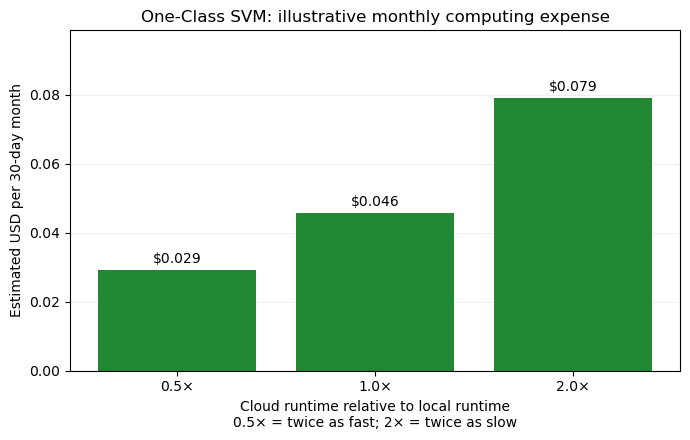

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar([f"{m}×" for m in cost_estimates["runtime multiplier"]],
              cost_estimates["estimated monthly USD"], color="#228833")
ax.bar_label(bars, fmt="$%.3f", padding=3)
ax.set_title("One-Class SVM: illustrative monthly computing expense")
ax.set_xlabel("Cloud runtime relative to local runtime\n0.5× = twice as fast; 2× = twice as slow")
ax.set_ylabel("Estimated USD per 30-day month")
ax.set_ylim(0, cost_estimates["estimated monthly USD"].max() * 1.25)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## Results

**Selected model.** Cross-validation on the training data selected **window = 10, telemetry-only features (7 columns), gamma = 0.001, nu = 0.01**, and **min_flags = 8** (the largest false cluster in validation had 7 flagged rows).

**Detection.** The One-Class SVM flagged 301 of the 8,495 scored test rows (3.5%). Merging flags at most 10 steps apart gives 48 candidate intervals. The `min_flags` filter cuts these to **6 alert intervals**. These overlap **all three known events (recall = 1.0)**, and only **2 are false alerts (precision = 0.60, F1 = 0.75)**. Without the filter, the merged alerts would include 43 false alerts (precision ≈ 0.07).

**Runtime.** The complete pipeline took about **124 ms per batch**: roughly 42 ms for feature generation and 88 ms for scoring, with interval construction negligible. Training takes about 32 ms per fit. Peak traced memory was about 1.8 MB for the pipeline and 0.4 MB for training.

**Cost.** Under the stated scenario, the estimated monthly expense is about **3.8, 6.4, and 11.5 cents** at 0.5×, 1×, and 2× runtime. At this runtime the 60-second minimum billing no longer sets the cost, even at 0.5×. A one-off training task costs less than a tenth of a cent. Keeping the same resources running continuously would cost **$35.55/month**, so the operating schedule matters far more than the processing time.

**Takeaway.** Running the SVM costs only a few cents per month. With the `min_flags` filter, false alerts drop from 43 to 2 while all three events are still caught, so the human time spent reviewing false alerts, which would most likely dominate the real cost, is much smaller than before.

*Exact timings vary between runs and with machine load; the figures above come from the executed run saved in this notebook.*

## Caveats

- These are batch-processing measurements on the computer running this notebook, not real-time latency or measured cloud results.
- Alert intervals depend on the merge gap (= feature window) and on `min_flags`. Both were fixed from training data before looking at labels, but they are still design choices. `min_flags = 8` also means a real anomaly that triggers fewer than 8 nearby flags would be missed.
- The configuration was chosen by validation FPR on normal-only training data, which does not directly measure the ability to catch anomalies.
- The selected model uses telemetry-only features, but `feature_engineering()` (kept identical to `SVM.ipynb`) still computes the command-column rolling sums before discarding them. A deployment that computes only the 7 telemetry features would have a shorter feature-generation time.
- Cost excludes human time spent investigating alerts, which grows with the number of false alerts.
- P-1 is a single-channel case study.